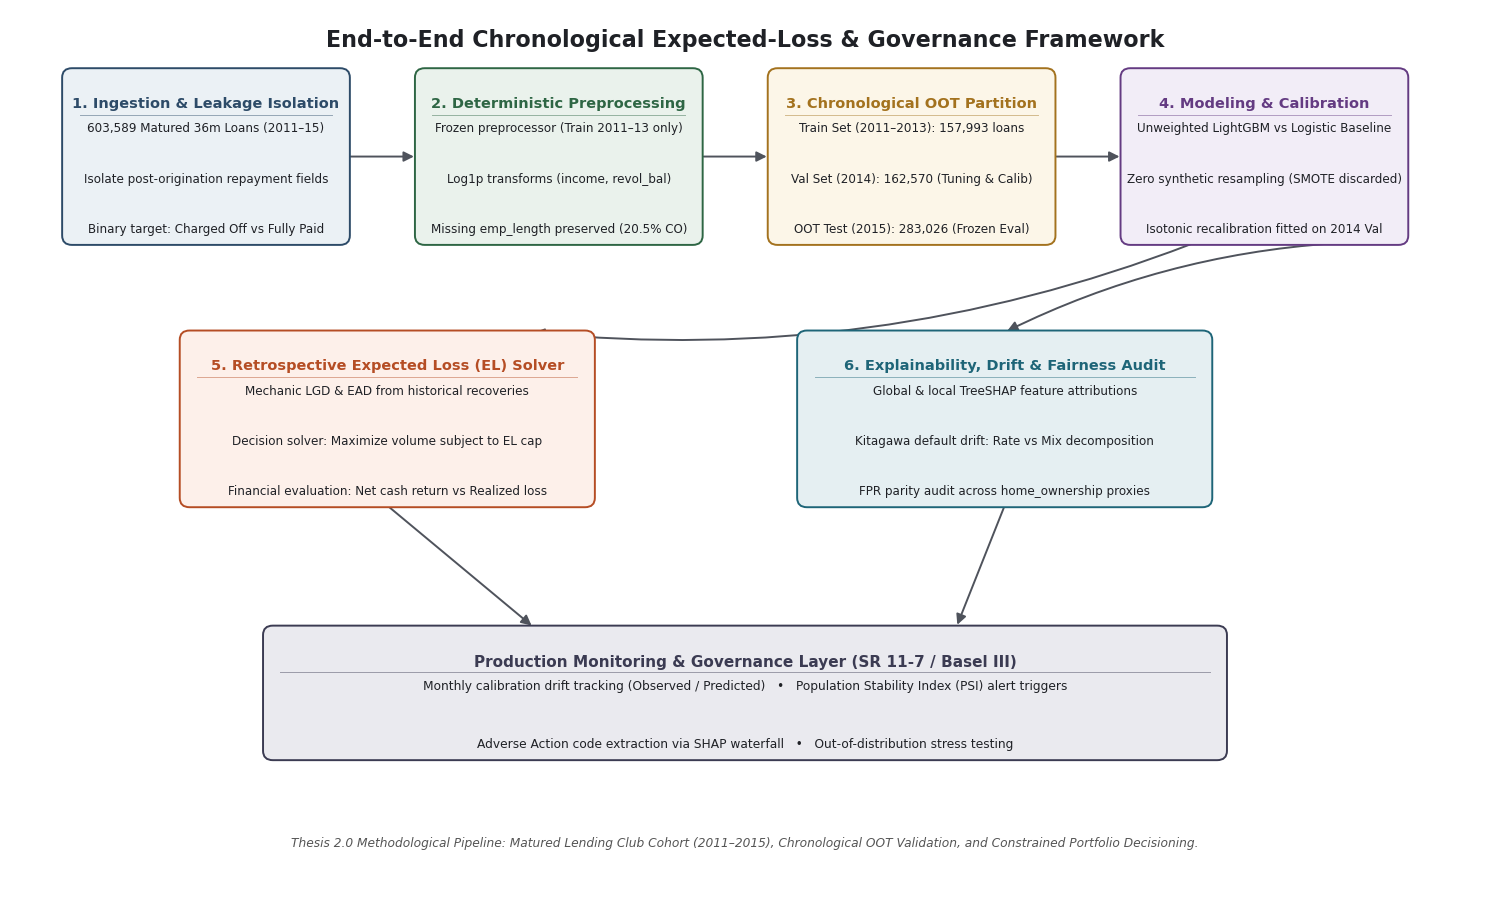

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

fig, ax = plt.subplots(figsize=(15, 9.2))
ax.set_xlim(0, 15)
ax.set_ylim(0, 9.5)
ax.axis("off")

# Professional palette aligned with Thesis 2.0 themes
c_data, e_data = "#EBF1F5", "#2D4B68"  # Ingestion & Cohort
c_prep, e_prep = "#EAF2EC", "#2E6644"  # Preprocessing
c_oot, e_oot = "#FCF6E8", "#A3721E"  # OOT Splits
c_model, e_model = "#F2EDF7", "#643B82"  # Calibration & Modeling
c_el, e_el = "#FDF0EA", "#B54D24"  # Cost-Sensitive Optimization
c_gov, e_gov = "#E5EFF2", "#1E6578"  # Governance & Audit
c_mon, e_mon = "#EAEAEF", "#3B3B52"  # Production Monitoring
txt_dark, arrow_c = "#1F2126", "#4F535C"


def draw_box(x, y, w, h, title, lines, fc, ec, fs_title=10.5, fs_line=8.6):
  b = FancyBboxPatch(
      (x, y),
      w,
      h,
      boxstyle="round,pad=0.018,rounding_size=0.10",
      linewidth=1.4,
      edgecolor=ec,
      facecolor=fc,
      zorder=2,
  )
  ax.add_patch(b)
  ax.text(
      x + w / 2,
      y + h - 0.28,
      title,
      ha="center",
      va="top",
      fontsize=fs_title,
      fontweight="bold",
      color=ec,
      zorder=3,
  )
  ax.plot(
      [x + 0.16, x + w - 0.16],
      [y + h - 0.48, y + h - 0.48],
      color=ec,
      linewidth=0.7,
      alpha=0.45,
      zorder=3,
  )
  n = len(lines)
  body_top, body_bot = y + h - 0.62, y + 0.16
  ys = (
      [(body_top + body_bot) / 2]
      if n == 1
      else [body_top - i * (body_top - body_bot) / (n - 1) for i in range(n)]
  )
  for line, ly in zip(lines, ys):
    ax.text(
        x + w / 2,
        ly,
        line,
        ha="center",
        va="center",
        fontsize=fs_line,
        color=txt_dark,
        zorder=3,
    )
  return {"x": x, "y": y, "w": w, "h": h}


def h_arrow(b1, b2):
  p1 = (b1["x"] + b1["w"], b1["y"] + b1["h"] / 2)
  p2 = (b2["x"], b2["y"] + b2["h"] / 2)
  ax.add_patch(
      FancyArrowPatch(
          p1,
          p2,
          arrowstyle="-|>",
          mutation_scale=15,
          linewidth=1.4,
          color=arrow_c,
          zorder=1,
          shrinkA=2,
          shrinkB=2,
      )
  )


# --- Row 1: Pipeline Pipeline Stages 1 -> 4 ---
w1, h1, gap1 = 2.9, 1.85, 0.7
y1, x0 = 7.0, 0.55

b1 = draw_box(
    x0,
    y1,
    w1,
    h1,
    "1. Ingestion & Leakage Isolation",
    [
        "603,589 Matured 36m Loans (2011–15)",
        "Isolate post-origination repayment fields",
        "Binary target: Charged Off vs Fully Paid",
    ],
    c_data,
    e_data,
)

b2 = draw_box(
    x0 + (w1 + gap1),
    y1,
    w1,
    h1,
    "2. Deterministic Preprocessing",
    [
        "Frozen preprocessor (Train 2011–13 only)",
        "Log1p transforms (income, revol_bal)",
        "Missing emp_length preserved (20.5% CO)",
    ],
    c_prep,
    e_prep,
)

b3 = draw_box(
    x0 + 2 * (w1 + gap1),
    y1,
    w1,
    h1,
    "3. Chronological OOT Partition",
    [
        "Train Set (2011–2013): 157,993 loans",
        "Val Set (2014): 162,570 (Tuning & Calib)",
        "OOT Test (2015): 283,026 (Frozen Eval)",
    ],
    c_oot,
    e_oot,
)

b4 = draw_box(
    x0 + 3 * (w1 + gap1),
    y1,
    w1,
    h1,
    "4. Modeling & Calibration",
    [
        "Unweighted LightGBM vs Logistic Baseline",
        "Zero synthetic resampling (SMOTE discarded)",
        "Isotonic recalibration fitted on 2014 Val",
    ],
    c_model,
    e_model,
)

h_arrow(b1, b2)
h_arrow(b2, b3)
h_arrow(b3, b4)

# --- Row 2: Optimization and Regulatory Governance ---
w2, h2, y2 = 4.2, 1.85, 4.2
x_el = x0 + 1.2
x_gov = x0 + 7.5

b5 = draw_box(
    x_el,
    y2,
    w2,
    h2,
    "5. Retrospective Expected Loss (EL) Solver",
    [
        "Mechanic LGD & EAD from historical recoveries",
        "Decision solver: Maximize volume subject to EL cap",
        "Financial evaluation: Net cash return vs Realized loss",
    ],
    c_el,
    e_el,
)

b6 = draw_box(
    x_gov,
    y2,
    w2,
    h2,
    "6. Explainability, Drift & Fairness Audit",
    [
        "Global & local TreeSHAP feature attributions",
        "Kitagawa default drift: Rate vs Mix decomposition",
        "FPR parity audit across home_ownership proxies",
    ],
    c_gov,
    e_gov,
)

# Connect Row 1 to Row 2
ax.add_patch(
    FancyArrowPatch(
        (b4["x"] + b4["w"] * 0.25, b4["y"]),
        (b5["x"] + b5["w"] * 0.85, b5["y"] + b5["h"]),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.4,
        color=arrow_c,
        zorder=1,
        connectionstyle="arc3,rad=-0.12",
        shrinkA=2,
        shrinkB=2,
    )
)

ax.add_patch(
    FancyArrowPatch(
        (b4["x"] + b4["w"] * 0.75, b4["y"]),
        (b6["x"] + b6["w"] * 0.5, b6["y"] + b6["h"]),
        arrowstyle="-|>",
        mutation_scale=15,
        linewidth=1.4,
        color=arrow_c,
        zorder=1,
        connectionstyle="arc3,rad=0.10",
        shrinkA=2,
        shrinkB=2,
    )
)

# --- Row 3: Deployment, Drift & Governance Monitoring Layer ---
w3, h3, y3 = 9.8, 1.4, 1.5
x3 = x0 + 2.05

b_deploy = draw_box(
    x3,
    y3,
    w3,
    h3,
    "Production Monitoring & Governance Layer (SR 11-7 / Basel III)",
    [
        (
            "Monthly calibration drift tracking (Observed / Predicted)   •  "
            " Population Stability Index (PSI) alert triggers"
        ),
        (
            "Adverse Action code extraction via SHAP waterfall   •  "
            " Out-of-distribution stress testing"
        ),
    ],
    c_mon,
    e_mon,
    fs_title=11.0,
    fs_line=8.8,
)

# Connect Row 2 to Row 3
for source, target_x in [(b5, 0.28), (b6, 0.72)]:
  ax.add_patch(
      FancyArrowPatch(
          (source["x"] + source["w"] * 0.5, source["y"]),
          (b_deploy["x"] + b_deploy["w"] * target_x, b_deploy["y"] + h3),
          arrowstyle="-|>",
          mutation_scale=15,
          linewidth=1.4,
          color=arrow_c,
          zorder=1,
          connectionstyle="arc3,rad=0.0",
          shrinkA=2,
          shrinkB=2,
      )
  )

# Header & Subtitle
ax.text(
    7.5,
    9.3,
    "End-to-End Chronological Expected-Loss & Governance Framework",
    ha="center",
    va="top",
    fontsize=16.0,
    fontweight="bold",
    color=txt_dark,
)
ax.text(
    7.5,
    0.6,
    "Thesis 2.0 Methodological Pipeline: Matured Lending Club Cohort"
    " (2011–2015), Chronological OOT Validation, and Constrained Portfolio"
    " Decisioning.",
    ha="center",
    va="center",
    fontsize=8.8,
    color="#555555",
    style="italic",
)

plt.tight_layout()
plt.savefig(
    "thesis_2_pipeline_architecture.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

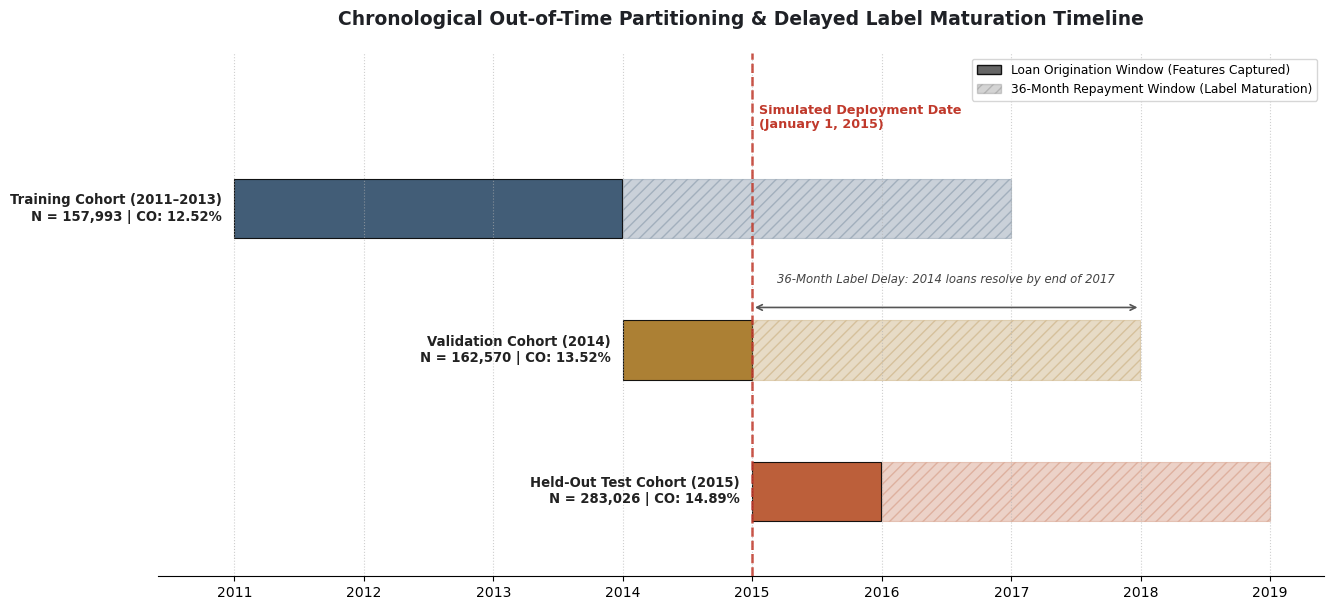

In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

fig, ax = plt.subplots(figsize=(13.5, 6.2))

# Timeline parameters (2011 through 2019)
start_date = pd.to_datetime("2011-01-01")
end_date = pd.to_datetime("2019-01-01")

vintages = [
    {
        "name": "Training Cohort (2011–2013)\nN = 157,993 | CO: 12.52%",
        "orig_start": "2011-01-01",
        "orig_end": "2013-12-31",
        "mat_start": "2014-01-01",
        "mat_end": "2016-12-31",
        "y": 2.5,
        "color": "#2D4B68",
    },
    {
        "name": "Validation Cohort (2014)\nN = 162,570 | CO: 13.52%",
        "orig_start": "2014-01-01",
        "orig_end": "2014-12-31",
        "mat_start": "2015-01-01",
        "mat_end": "2017-12-31",
        "y": 1.5,
        "color": "#A3721E",
    },
    {
        "name": "Held-Out Test Cohort (2015)\nN = 283,026 | CO: 14.89%",
        "orig_start": "2015-01-01",
        "orig_end": "2015-12-31",
        "mat_start": "2016-01-01",
        "mat_end": "2018-12-31",
        "y": 0.5,
        "color": "#B54D24",
    },
]

for v in vintages:
  o_start = mdates.date2num(pd.to_datetime(v["orig_start"]))
  o_end = mdates.date2num(pd.to_datetime(v["orig_end"]))
  m_start = mdates.date2num(pd.to_datetime(v["mat_start"]))
  m_end = mdates.date2num(pd.to_datetime(v["mat_end"]))
  y = v["y"]

  # Origination Bar
  ax.barh(
      y,
      o_end - o_start,
      left=o_start,
      height=0.42,
      color=v["color"],
      alpha=0.90,
      edgecolor="black",
      linewidth=0.8,
  )

  # 36-Month Maturation / Performance Window Bar (Hatched)
  ax.barh(
      y,
      m_end - m_start,
      left=m_start,
      height=0.42,
      color=v["color"],
      alpha=0.25,
      edgecolor=v["color"],
      hatch="///",
      linewidth=0.8,
  )

  # Cohort Label on the left
  ax.text(
      o_start - 35,
      y,
      v["name"],
      va="center",
      ha="right",
      fontsize=9.5,
      fontweight="bold",
      color="#222222",
  )

# Vertical marker for Simulated Deployment Cutoff (Jan 1, 2015)
cutoff = mdates.date2num(pd.to_datetime("2015-01-01"))
ax.axvline(
    cutoff,
    color="#C0392B",
    linestyle="--",
    linewidth=1.8,
    zorder=5,
    alpha=0.85,
)
ax.text(
    cutoff + 20,
    3.05,
    "Simulated Deployment Date\n(January 1, 2015)",
    color="#C0392B",
    fontsize=9.2,
    fontweight="bold",
    va="bottom",
    ha="left",
)

# Annotate the Delayed Label Delimitation Gap
gap_start = mdates.date2num(pd.to_datetime("2015-01-01"))
gap_end = mdates.date2num(pd.to_datetime("2017-12-31"))
ax.annotate(
    "",
    xy=(gap_end, 1.8),
    xytext=(gap_start, 1.8),
    arrowprops=dict(arrowstyle="<->", color="#555555", lw=1.2),
)
ax.text(
    (gap_start + gap_end) / 2,
    1.95,
    "36-Month Label Delay: 2014 loans resolve by end of 2017",
    ha="center",
    va="bottom",
    fontsize=8.4,
    color="#444444",
    style="italic",
)

# Format X-axis with Year Ticks
ax.set_xlim(
    mdates.date2num(pd.to_datetime("2010-06-01")),
    mdates.date2num(pd.to_datetime("2019-06-01")),
)
ax.set_ylim(-0.1, 3.6)
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.6)

# Legend
orig_patch = plt.Rectangle(
    (0, 0),
    1,
    1,
    fc="#555555",
    alpha=0.9,
    edgecolor="black",
    label="Loan Origination Window (Features Captured)",
)
mat_patch = plt.Rectangle(
    (0, 0),
    1,
    1,
    fc="#555555",
    alpha=0.25,
    hatch="///",
    edgecolor="#555555",
    label="36-Month Repayment Window (Label Maturation)",
)
ax.legend(
    handles=[orig_patch, mat_patch],
    loc="upper right",
    frameon=True,
    fontsize=8.8,
)

ax.set_title(
    "Chronological Out-of-Time Partitioning & Delayed Label Maturation"
    " Timeline",
    fontsize=13.5,
    fontweight="bold",
    pad=20,
    color="#1F2126",
)

plt.tight_layout()
plt.savefig(
    "chronological_oot_timeline.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()

SWOT Analysis

In [3]:
# ================================================================
# SWOT ANALYSIS TABLE
# ================================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties

# ----------------------------------------------------------------
# Font setup
# ----------------------------------------------------------------
# Use a font that is normally bundled with Matplotlib.
# This avoids "findfont" warnings for Helvetica / Inter.
FONT = "DejaVu Sans"

plt.rcParams["font.family"] = FONT
plt.rcParams["font.sans-serif"] = [FONT]

# ----------------------------------------------------------------
# Colours
# ----------------------------------------------------------------
INK = "#2F3640"
MUTED = "#6B7280"
LINE = "#E3E6EB"
HEADER = "#EDF0F5"
WHITE = "#FFFFFF"

PASTEL = {
    "Strengths": "#E4F1E8",
    "Weaknesses": "#F8E3E3",
    "Opportunities": "#E2ECF8",
    "Threats": "#FAF0D9",
}

# ----------------------------------------------------------------
# Typography / layout
# ----------------------------------------------------------------
FS = 9.0
FS_H = 9.5
LINE_H = 0.165
PAD = 0.11
BULLET_INDENT = 0.13

_fp = FontProperties(family=FONT, size=FS)
_fp_bold = FontProperties(family=FONT, size=FS, weight="bold")


# ----------------------------------------------------------------
# Helper functions
# ----------------------------------------------------------------
def text_w(s, bold=False):
    """Return text width in inches."""
    fp = _fp_bold if bold else _fp

    if not s.strip():
        return 0.0

    return TextPath(
        (0, 0),
        s,
        size=FS,
        prop=fp
    ).get_extents().width / 72


def wrap(text, width, bold=False):
    """Greedy word wrap to a specified width in inches."""
    lines = []
    cur = ""

    for word in text.split():
        trial = f"{cur} {word}".strip()

        if text_w(trial, bold) <= width or not cur:
            cur = trial
        else:
            lines.append(cur)
            cur = word

    if cur:
        lines.append(cur)

    return lines or [""]


def blend(hex_color, amount=0.5):
    """Blend a colour with white."""
    h = hex_color.lstrip("#")

    r, g, b = (
        int(h[i:i + 2], 16)
        for i in (0, 2, 4)
    )

    r, g, b = (
        round(c + (255 - c) * amount)
        for c in (r, g, b)
    )

    return f"#{r:02X}{g:02X}{b:02X}"


# ----------------------------------------------------------------
# SWOT rendering function
# ----------------------------------------------------------------
def render_swot(
    title,
    subtitle,
    col_names,
    col_widths,
    header_fills,
    rows,
    filename,
    bold_cols=(),
    merge_col=None
):
    """
    Render the SWOT table and save it as PNG and PDF.
    """

    # ------------------------------------------------------------
    # Measure rows
    # ------------------------------------------------------------
    heights = []
    wrapped = []

    for r in rows:

        cell_lines = []
        max_lines = 1

        for ci, cell in enumerate(r["cells"]):

            inner = col_widths[ci] - 2 * PAD

            if isinstance(cell, list):

                ls = [
                    wrap(
                        item,
                        inner - BULLET_INDENT
                    )
                    for item in cell
                ]

                n = sum(len(x) for x in ls)

            else:

                ls = wrap(
                    cell,
                    inner,
                    bold=(ci in bold_cols)
                )

                n = len(ls)

            cell_lines.append(ls)

            if ci != merge_col:
                max_lines = max(max_lines, n)

        wrapped.append(cell_lines)

        heights.append(
            max_lines * LINE_H + 2 * PAD
        )

    # ------------------------------------------------------------
    # Figure dimensions
    # ------------------------------------------------------------
    header_h = 0.42
    title_h = 0.75

    total_w = sum(col_widths)
    total_h = (
        title_h
        + header_h
        + sum(heights)
        + 0.25
    )

    margin = 0.3

    fig = plt.figure(
        figsize=(
            total_w + 2 * margin,
            total_h + margin
        ),
        facecolor=WHITE
    )

    ax = fig.add_axes([0, 0, 1, 1])

    ax.set_xlim(
        0,
        total_w + 2 * margin
    )

    ax.set_ylim(
        total_h + margin,
        0
    )

    ax.axis("off")

    # ------------------------------------------------------------
    # Title
    # ------------------------------------------------------------
    x0 = margin
    y = margin * 0.6

    ax.text(
        x0,
        y + 0.2,
        title,
        fontsize=14,
        fontweight="bold",
        color=INK,
        va="center"
    )

    if subtitle:
        ax.text(
            x0,
            y + 0.48,
            subtitle,
            fontsize=9,
            color=MUTED,
            va="center"
        )

    y += title_h

    # ------------------------------------------------------------
    # Header
    # ------------------------------------------------------------
    x = x0

    for name, w, fill in zip(
        col_names,
        col_widths,
        header_fills
    ):

        ax.add_patch(
            Rectangle(
                (x, y),
                w,
                header_h,
                facecolor=fill,
                edgecolor="none"
            )
        )

        ax.text(
            x + PAD,
            y + header_h / 2,
            name,
            fontsize=FS_H,
            fontweight="bold",
            color=INK,
            va="center"
        )

        x += w

    y += header_h

    # ------------------------------------------------------------
    # Body
    # ------------------------------------------------------------
    group_start = {}
    y_cursor = y

    for ri, r in enumerate(rows):

        h = heights[ri]
        x = x0

        for ci, (w, fill) in enumerate(
            zip(col_widths, r["fills"])
        ):

            # Skip merged column while drawing body cells
            if ci == merge_col:
                x += w
                continue

            ax.add_patch(
                Rectangle(
                    (x, y_cursor),
                    w,
                    h,
                    facecolor=fill,
                    edgecolor="none"
                )
            )

            cell = r["cells"][ci]
            ls = wrapped[ri][ci]

            ty = (
                y_cursor
                + PAD
                + LINE_H / 2
            )

            # ----------------------------------------------------
            # Bullet list
            # ----------------------------------------------------
            if isinstance(cell, list):

                for item_lines in ls:

                    ax.text(
                        x + PAD,
                        ty,
                        "•",
                        fontsize=FS,
                        color=MUTED,
                        va="center"
                    )

                    for ln in item_lines:

                        ax.text(
                            x + PAD + BULLET_INDENT,
                            ty,
                            ln,
                            fontsize=FS,
                            color=INK,
                            va="center"
                        )

                        ty += LINE_H

            # ----------------------------------------------------
            # Normal text
            # ----------------------------------------------------
            else:

                bold = ci in bold_cols

                for ln in ls:

                    ax.text(
                        x + PAD,
                        ty,
                        ln,
                        fontsize=FS,
                        color=INK,
                        fontweight=(
                            "bold" if bold else "normal"
                        ),
                        va="center"
                    )

                    ty += LINE_H

            x += w

        # --------------------------------------------------------
        # Row separator
        # --------------------------------------------------------
        ax.plot(
            [x0, x0 + total_w],
            [y_cursor + h, y_cursor + h],
            color=LINE,
            lw=0.6
        )

        # --------------------------------------------------------
        # Track merged groups
        # --------------------------------------------------------
        if merge_col is not None:

            g = r["group"]

            group_start.setdefault(
                g,
                [
                    y_cursor,
                    0.0,
                    r["cells"][merge_col]
                ]
            )

            group_start[g][1] += h

        y_cursor += h

    # ------------------------------------------------------------
    # Merged first column
    # ------------------------------------------------------------
    if merge_col is not None:

        mx = (
            x0
            + sum(col_widths[:merge_col])
        )

        mw = col_widths[merge_col]

        for g, (gy, gh, label) in group_start.items():

            ax.add_patch(
                Rectangle(
                    (mx, gy),
                    mw,
                    gh,
                    facecolor=WHITE,
                    edgecolor="none"
                )
            )

            lines = wrap(
                label,
                mw - 2 * PAD,
                bold=True
            )

            ty = (
                gy
                + gh / 2
                - (len(lines) - 1)
                * LINE_H / 2
            )

            for ln in lines:

                ax.text(
                    mx + PAD,
                    ty,
                    ln,
                    fontsize=FS,
                    fontweight="bold",
                    color=INK,
                    va="center"
                )

                ty += LINE_H

            # Stronger group separator
            ax.plot(
                [x0, x0 + total_w],
                [gy + gh, gy + gh],
                color="#CBD1DA",
                lw=1.0
            )

    # ------------------------------------------------------------
    # Top frame
    # ------------------------------------------------------------
    ax.plot(
        [x0, x0 + total_w],
        [y, y],
        color="#CBD1DA",
        lw=1.0
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    fig.savefig(
        f"{filename}.png",
        dpi=220,
        facecolor=WHITE,
        bbox_inches="tight"
    )

    fig.savefig(
        f"{filename}.pdf",
        facecolor=WHITE,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print(
        f"Saved: {filename}.png"
    )
    print(
        f"Saved: {filename}.pdf"
    )


# ================================================================
# SWOT DATA
# ================================================================

SWOT = [

    (
        "Traditional scorecard",
        "Strengths",
        [
            "High transparency.",
            "Easy to document and challenge.",
            "Familiar to credit-risk practitioners.",
            "Suitable as a benchmark."
        ]
    ),

    (
        "Traditional scorecard",
        "Weaknesses",
        [
            "May underrepresent nonlinear interactions.",
            "Requires careful binning, transformations, and stability monitoring.",
            "Can be less flexible for complex feature relationships."
        ]
    ),

    (
        "Traditional scorecard",
        "Opportunities",
        [
            "Combine with monotonic constraints, scorecard development, and calibration.",
            "Use as a challenger model against boosting."
        ]
    ),

    (
        "Traditional scorecard",
        "Threats",
        [
            "May be outperformed on discrimination by well-governed ensemble models.",
            "Can become outdated when borrower populations or economic conditions change."
        ]
    ),

    (
        "Academic machine-learning benchmark",
        "Strengths",
        [
            "Rapid experimentation.",
            "Broad algorithm comparison.",
            "Low licensing cost.",
            "Useful for methodological teaching."
        ]
    ),

    (
        "Academic machine-learning benchmark",
        "Weaknesses",
        [
            "Random splits can overstate future performance.",
            "Preprocessing can leak information.",
            "Accuracy or F1 may be prioritised over PD calibration.",
            "Static thresholds may ignore financial costs.",
            "Explanations may be added after modelling without connecting them to governance."
        ]
    ),

    (
        "Academic machine-learning benchmark",
        "Opportunities",
        [
            "Improve using out-of-time validation, calibration, leakage controls, and decision-cost analysis."
        ]
    ),

    (
        "Academic machine-learning benchmark",
        "Threats",
        [
            "Misleading reported performance.",
            "Poor reproducibility.",
            "Inappropriate deployment or regulatory interpretation."
        ]
    ),

    (
        "Commercial AI platform",
        "Strengths",
        [
            "Integrated experiment tracking, deployment, monitoring, and governance.",
            "Potentially faster operationalisation.",
            "Support for model comparison and workflow automation."
        ]
    ),

    (
        "Commercial AI platform",
        "Weaknesses",
        [
            "Cost and vendor lock-in.",
            "Proprietary components may limit independent auditability.",
            "Outputs still depend on the institution's data, target, and validation design."
        ]
    ),

    (
        "Commercial AI platform",
        "Opportunities",
        [
            "Used as an implementation environment after a sound research methodology has been established."
        ]
    ),

    (
        "Commercial AI platform",
        "Threats",
        [
            "Automation can create false confidence.",
            "Governance weaknesses may be hidden behind a polished interface."
        ]
    ),

    (
        "Proposed framework",
        "Strengths",
        [
            "Uses 603,589 resolved 36-month loans rather than the earlier small snapshot.",
            "Explicitly defines the target.",
            "Uses chronological train, validation, and test periods.",
            "Separates PD inputs from repayment outcomes.",
            "Stores raw, processed, feature-rule, and preprocessing artifacts.",
            "Compares a borrower/application baseline with a lender-pricing feature set.",
            "Supports calibration, SHAP, and later Expected Loss analysis."
        ]
    ),

    (
        "Proposed framework",
        "Weaknesses",
        [
            "Historical Lending Club data do not represent all lenders or all applicants.",
            "The cohort contains originated loans only.",
            "The target is final observed status, not a fixed-horizon PD.",
            "No full protected-group fairness audit is currently possible.",
            "LGD and EAD are not yet empirically validated.",
            "The current system is a reproducible research pipeline, not a production lending platform."
        ]
    ),

    (
        "Proposed framework",
        "Opportunities",
        [
            "Add calibrated PD models.",
            "Compare Logistic Regression with LightGBM or another ensemble.",
            "Add SHAP explanations.",
            "Estimate or scenario-test LGD and EAD.",
            "Add population-stability and performance-drift monitoring.",
            "Add fairness analysis when appropriate governed data are available."
        ]
    ),

    (
        "Proposed framework",
        "Threats",
        [
            "Label and cohort selection bias.",
            "Vintage and economic drift.",
            "Data-source changes.",
            "Misinterpretation of illustrative fairness or Expected Loss assumptions.",
            "Overclaiming regulatory compliance from explainability alone."
        ]
    )
]


# ================================================================
# BUILD SWOT TABLE
# ================================================================

rows = []

for fw, cat, items in SWOT:

    color = PASTEL[cat]

    rows.append({
        "group": fw,
        "cells": [
            fw,
            cat,
            items
        ],
        "fills": [
            WHITE,
            color,
            blend(color, 0.55)
        ]
    })


render_swot(
    title="SWOT Analysis",
    subtitle="Credit-risk modelling frameworks",

    col_names=[
        "Framework",
        "SWOT Category",
        "Details"
    ],

    col_widths=[
        1.9,
        1.35,
        5.6
    ],

    header_fills=[
        HEADER,
        HEADER,
        HEADER
    ],

    rows=rows,

    filename="swot_table",

    bold_cols=(1,),

    merge_col=0
)

Saved: swot_table.png
Saved: swot_table.pdf


C:\Users\Yahya\AppData\Local\Temp\ipykernel_10568\1662990509.py:479: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Comparative Analysis

In [4]:
# ================================================================
# COMPARATIVE ANALYSIS TABLE
# ================================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties

# ----------------------------------------------------------------
# Font setup
# ----------------------------------------------------------------
FONT = "DejaVu Sans"

plt.rcParams["font.family"] = FONT
plt.rcParams["font.sans-serif"] = [FONT]

# ----------------------------------------------------------------
# Colours
# ----------------------------------------------------------------
INK = "#2F3640"
MUTED = "#6B7280"
LINE = "#E3E6EB"
HEADER = "#EDF0F5"
ZEBRA = "#F8F9FB"
WHITE = "#FFFFFF"

PASTEL = {
    "Strengths": "#E4F1E8",
    "Weaknesses": "#F8E3E3",
    "Opportunities": "#E2ECF8",
}

HIGHLIGHT = "#EEEAF7"

# ----------------------------------------------------------------
# Typography / layout
# ----------------------------------------------------------------
FS = 9.0
FS_H = 9.5
LINE_H = 0.165
PAD = 0.11

_fp = FontProperties(
    family=FONT,
    size=FS
)

_fp_bold = FontProperties(
    family=FONT,
    size=FS,
    weight="bold"
)


# ----------------------------------------------------------------
# Helper functions
# ----------------------------------------------------------------
def text_w(s, bold=False):
    """Return text width in inches."""

    fp = _fp_bold if bold else _fp

    if not s.strip():
        return 0.0

    return TextPath(
        (0, 0),
        s,
        size=FS,
        prop=fp
    ).get_extents().width / 72


def wrap(text, width, bold=False):
    """Greedy word wrap."""

    lines = []
    cur = ""

    for word in text.split():

        trial = f"{cur} {word}".strip()

        if text_w(trial, bold) <= width or not cur:
            cur = trial
        else:
            lines.append(cur)
            cur = word

    if cur:
        lines.append(cur)

    return lines or [""]


# ----------------------------------------------------------------
# Comparative table renderer
# ----------------------------------------------------------------
def render_comparative(
    title,
    subtitle,
    col_names,
    col_widths,
    header_fills,
    rows,
    filename,
    bold_cols=()
):

    # ------------------------------------------------------------
    # Measure rows
    # ------------------------------------------------------------
    heights = []
    wrapped = []

    for r in rows:

        cell_lines = []
        max_lines = 1

        for ci, cell in enumerate(r["cells"]):

            inner = col_widths[ci] - 2 * PAD

            ls = wrap(
                cell,
                inner,
                bold=(ci in bold_cols)
            )

            cell_lines.append(ls)

            max_lines = max(
                max_lines,
                len(ls)
            )

        wrapped.append(cell_lines)

        heights.append(
            max_lines * LINE_H + 2 * PAD
        )

    # ------------------------------------------------------------
    # Figure dimensions
    # ------------------------------------------------------------
    header_h = 0.42
    title_h = 0.75

    total_w = sum(col_widths)

    total_h = (
        title_h
        + header_h
        + sum(heights)
        + 0.25
    )

    margin = 0.3

    fig = plt.figure(
        figsize=(
            total_w + 2 * margin,
            total_h + margin
        ),
        facecolor=WHITE
    )

    ax = fig.add_axes([0, 0, 1, 1])

    ax.set_xlim(
        0,
        total_w + 2 * margin
    )

    ax.set_ylim(
        total_h + margin,
        0
    )

    ax.axis("off")

    # ------------------------------------------------------------
    # Title
    # ------------------------------------------------------------
    x0 = margin
    y = margin * 0.6

    ax.text(
        x0,
        y + 0.2,
        title,
        fontsize=14,
        fontweight="bold",
        color=INK,
        va="center"
    )

    if subtitle:

        ax.text(
            x0,
            y + 0.48,
            subtitle,
            fontsize=9,
            color=MUTED,
            va="center"
        )

    y += title_h

    # ------------------------------------------------------------
    # Header
    # ------------------------------------------------------------
    x = x0

    for name, w, fill in zip(
        col_names,
        col_widths,
        header_fills
    ):

        ax.add_patch(
            Rectangle(
                (x, y),
                w,
                header_h,
                facecolor=fill,
                edgecolor="none"
            )
        )

        ax.text(
            x + PAD,
            y + header_h / 2,
            name,
            fontsize=FS_H,
            fontweight="bold",
            color=INK,
            va="center"
        )

        x += w

    y += header_h

    # ------------------------------------------------------------
    # Body
    # ------------------------------------------------------------
    y_cursor = y

    for ri, r in enumerate(rows):

        h = heights[ri]
        x = x0

        for ci, (w, fill) in enumerate(
            zip(col_widths, r["fills"])
        ):

            ax.add_patch(
                Rectangle(
                    (x, y_cursor),
                    w,
                    h,
                    facecolor=fill,
                    edgecolor="none"
                )
            )

            cell = r["cells"][ci]
            ls = wrapped[ri][ci]

            ty = (
                y_cursor
                + PAD
                + LINE_H / 2
            )

            bold = ci in bold_cols

            for ln in ls:

                ax.text(
                    x + PAD,
                    ty,
                    ln,
                    fontsize=FS,
                    color=INK,
                    fontweight=(
                        "bold" if bold else "normal"
                    ),
                    va="center"
                )

                ty += LINE_H

            x += w

        # --------------------------------------------------------
        # Row separator
        # --------------------------------------------------------
        ax.plot(
            [x0, x0 + total_w],
            [y_cursor + h, y_cursor + h],
            color=LINE,
            lw=0.6
        )

        y_cursor += h

    # ------------------------------------------------------------
    # Top frame
    # ------------------------------------------------------------
    ax.plot(
        [x0, x0 + total_w],
        [y, y],
        color="#CBD1DA",
        lw=1.0
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    fig.savefig(
        f"{filename}.png",
        dpi=220,
        facecolor=WHITE,
        bbox_inches="tight"
    )

    fig.savefig(
        f"{filename}.pdf",
        facecolor=WHITE,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

    print(
        f"Saved: {filename}.png"
    )

    print(
        f"Saved: {filename}.pdf"
    )


# ================================================================
# COMPARATIVE ANALYSIS DATA
# ================================================================

COMPARATIVE = [

    (
        "Logistic Regression / scorecard",

        "Transparent coefficients; easy benchmarking; "
        "familiar governance; relatively simple calibration",

        "May miss nonlinear interactions; requires careful "
        "transformations and feature design",

        "Primary interpretable benchmark"
    ),

    (
        "Random Forest / gradient boosting",

        "Captures nonlinear effects and interactions; "
        "often strong tabular performance",

        "More difficult to explain directly; can require "
        "calibration and tuning; may be unstable under drift",

        "Candidate nonlinear comparison"
    ),

    (
        "Naive academic ML benchmark",

        "Easy to implement; low software cost; "
        "useful for teaching",

        "Often uses random splits, leakage-prone preprocessing, "
        "immature labels, and accuracy-focused metrics",

        "The revised workflow is designed to correct these weaknesses"
    ),

    (
        "Commercial AI platforms",

        "Integrated deployment, monitoring, governance, "
        "and experimentation tools",

        "Licensing cost, vendor dependence, restricted "
        "transparency, and implementation complexity",

        "Industry comparator, not a direct numerical benchmark"
    ),

    (
        "Internal institutional scorecard",

        "Access to proprietary data, policies, protected-group "
        "monitoring, and operational outcomes",

        "High development, governance, and "
        "data-integration requirements",

        "More realistic production reference"
    ),

    (
        "Proposed framework",

        "Reproducible open-source workflow; historical cohort "
        "selection; chronological validation; separate outcome "
        "table; explainability-ready architecture",

        "Not production validated; no live data; no verified "
        "protected-group data; LGD/EAD not yet empirically modelled",

        "Academic proof of concept and methodological framework"
    )
]


# ================================================================
# BUILD COMPARATIVE TABLE
# ================================================================

rows = []

for i, (approach, strengths, weaknesses, relevance) in enumerate(
    COMPARATIVE
):

    proposed = (
        approach == "Proposed framework"
    )

    base = (
        HIGHLIGHT
        if proposed
        else (
            WHITE
            if i % 2 == 0
            else ZEBRA
        )
    )

    rows.append({
        "cells": [
            approach,
            strengths,
            weaknesses,
            relevance
        ],

        "fills": [
            base,
            base,
            base,
            base
        ]
    })


render_comparative(
    title="Comparative Analysis",

    subtitle=(
        "Modelling approaches and their relevance "
        "to this project"
    ),

    col_names=[
        "Approach",
        "Strengths",
        "Weaknesses",
        "Relevance to this project"
    ],

    col_widths=[
        1.7,
        2.7,
        2.9,
        2.2
    ],

    header_fills=[
        HEADER,
        PASTEL["Strengths"],
        PASTEL["Weaknesses"],
        PASTEL["Opportunities"]
    ],

    rows=rows,

    filename="comparative_table",

    bold_cols=(0,)
)

Saved: comparative_table.png
Saved: comparative_table.pdf


C:\Users\Yahya\AppData\Local\Temp\ipykernel_10568\1604040243.py:339: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


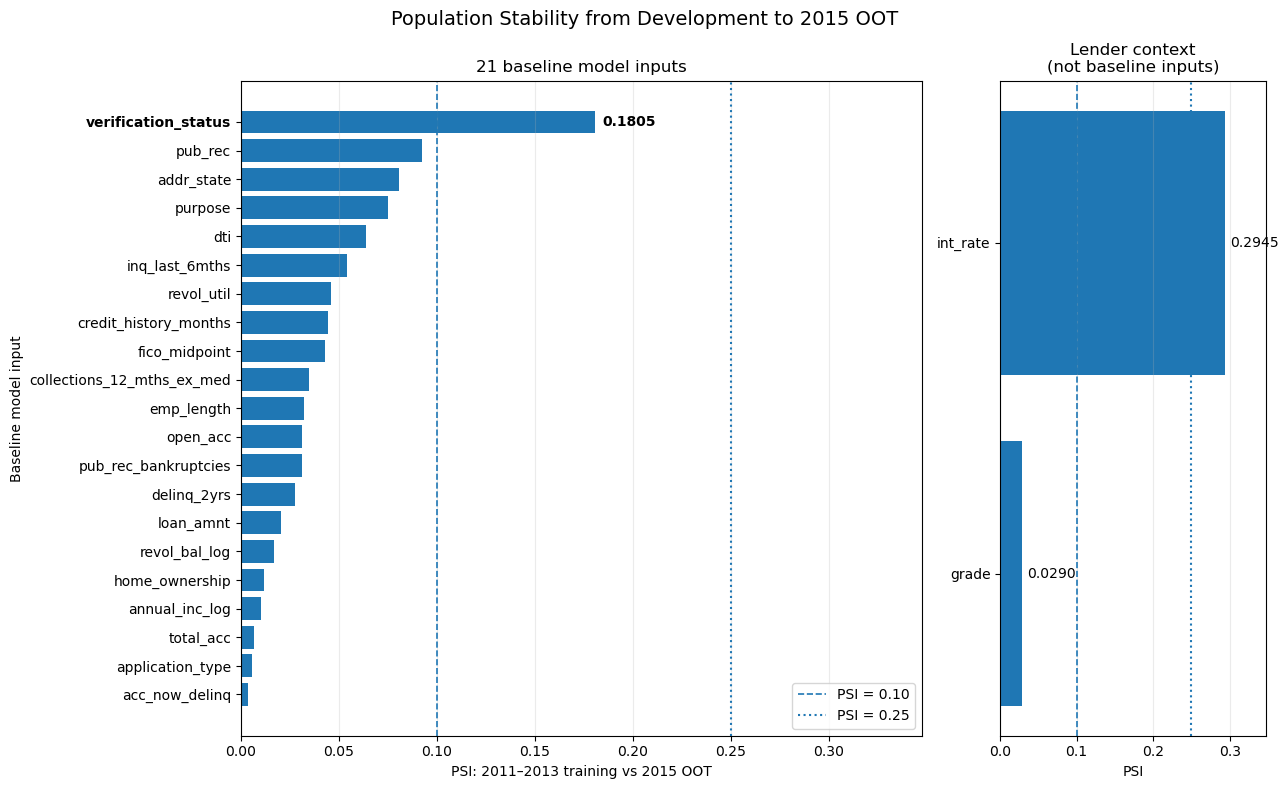

Saved:
C:\Users\Yahya\Desktop\dynamic-credit-risk-xai\reports\figures\04b_psi_model_inputs_and_context.png
C:\Users\Yahya\Desktop\dynamic-credit-risk-xai\reports\figures\04b_psi_model_inputs_and_context.pdf


In [1]:
# Figure 4.3 — PSI of baseline model inputs and lender-context variables

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------

project_root = Path.cwd().resolve().parent

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------
# Load PSI results produced by Notebook 04b
# ------------------------------------------------------------------

psi_file = tables_dir / "04b_psi_model_inputs.csv"

psi = pd.read_csv(psi_file)

# We want the training-period to 2015 OOT comparison.
plot_data = (
    psi[
        [
            "feature",
            "psi_train_vs_2015",
        ]
    ]
    .copy()
    .sort_values("psi_train_vs_2015", ascending=True)
)

# Context variables reported in Notebook 04b.
# These are deliberately kept separate because they are NOT
# inputs to the frozen 21-feature baseline model.
context = pd.DataFrame(
    {
        "variable": [
            "grade",
            "int_rate",
        ],
        "psi_train_vs_2015": [
            0.0290,
            0.2945,
        ],
    }
).sort_values("psi_train_vs_2015", ascending=True)


# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 8),
    gridspec_kw={"width_ratios": [3.2, 1.25]},
)

ax = axes[0]

bars = ax.barh(
    plot_data["feature"],
    plot_data["psi_train_vs_2015"],
)

# Conventional descriptive PSI reference levels.
ax.axvline(
    0.10,
    linestyle="--",
    linewidth=1.2,
    label="PSI = 0.10",
)

ax.axvline(
    0.25,
    linestyle=":",
    linewidth=1.5,
    label="PSI = 0.25",
)

ax.set_xlabel("PSI: 2011–2013 training vs 2015 OOT")
ax.set_ylabel("Baseline model input")
ax.set_title("21 baseline model inputs")
ax.grid(axis="x", alpha=0.25)

# Make verification_status visually noticeable without relying
# on a separate manually chosen colour.
for tick in ax.get_yticklabels():
    if tick.get_text() == "verification_status":
        tick.set_fontweight("bold")

# Annotate the verification_status bar.
verification_value = plot_data.loc[
    plot_data["feature"] == "verification_status",
    "psi_train_vs_2015",
].iloc[0]

verification_position = plot_data.reset_index(drop=True).index[
    plot_data.reset_index(drop=True)["feature"] == "verification_status"
][0]

ax.text(
    verification_value + 0.004,
    verification_position,
    f"{verification_value:.4f}",
    va="center",
    fontweight="bold",
)

ax.legend(loc="lower right")


# ------------------------------------------------------------------
# Context variables panel
# ------------------------------------------------------------------

ax_context = axes[1]

ax_context.barh(
    context["variable"],
    context["psi_train_vs_2015"],
)

ax_context.axvline(
    0.10,
    linestyle="--",
    linewidth=1.2,
)

ax_context.axvline(
    0.25,
    linestyle=":",
    linewidth=1.5,
)

for y, value in enumerate(context["psi_train_vs_2015"]):
    ax_context.text(
        value + 0.006,
        y,
        f"{value:.4f}",
        va="center",
    )

ax_context.set_xlabel("PSI")
ax_context.set_title(
    "Lender context\n(not baseline inputs)"
)
ax_context.grid(axis="x", alpha=0.25)


# Keep the same x-scale across both panels.
max_psi = max(
    plot_data["psi_train_vs_2015"].max(),
    context["psi_train_vs_2015"].max(),
)

x_upper = max_psi * 1.18

ax.set_xlim(0, x_upper)
ax_context.set_xlim(0, x_upper)


# ------------------------------------------------------------------
# Final formatting and export
# ------------------------------------------------------------------

fig.suptitle(
    "Population Stability from Development to 2015 OOT",
    fontsize=14,
)

fig.tight_layout()

png_file = figures_dir / "04b_psi_model_inputs_and_context.png"
pdf_file = figures_dir / "04b_psi_model_inputs_and_context.pdf"

fig.savefig(
    png_file,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    pdf_file,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(png_file)
print(pdf_file)

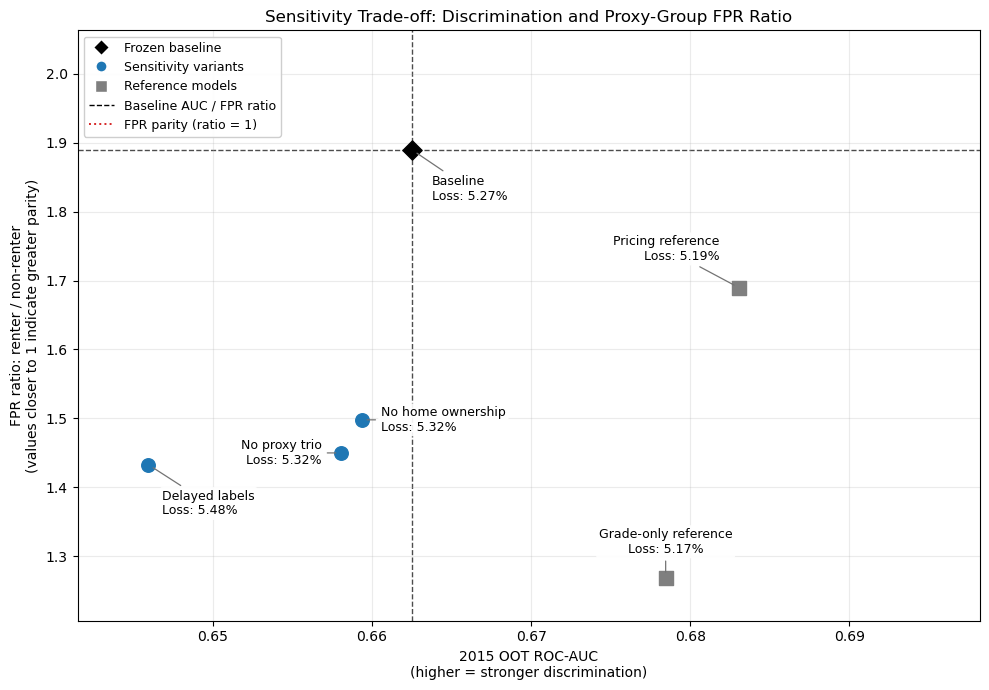

Saved:
C:\Users\Yahya\Desktop\dynamic-credit-risk-xai\reports\figures\04c_sensitivity_auc_vs_fpr_ratio.png
C:\Users\Yahya\Desktop\dynamic-credit-risk-xai\reports\figures\04c_sensitivity_auc_vs_fpr_ratio.pdf


,label,auc,fpr_ratio,approval_ratio_renter_vs_non,realized_loss_rate_approved
0,Baseline,0.6625,1.8894,0.7521,0.0527
1,No home ownership,0.6593,1.4977,0.8327,0.0532
2,No proxy trio,0.6581,1.4497,0.8453,0.0532
3,Delayed labels,0.6459,1.4325,0.8489,0.0548
4,Pricing reference,0.6831,1.6896,0.8279,0.0519
5,Grade-only reference,0.6784,1.2685,0.9229,0.0517


In [12]:
# Figure 4.5 — Sensitivity trade-off:
# 2015 ROC-AUC versus renter/non-renter FPR ratio

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------
project_root = Path.cwd().resolve().parent
tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------------
# Load Notebook 04c results
# ------------------------------------------------------------------
quality = pd.read_csv(tables_dir / "04c_variant_model_quality.csv")
policy = pd.read_csv(tables_dir / "04c_variant_policy_outcomes.csv")

quality["period"] = quality["period"].astype(str)

quality_2015 = quality.loc[
    (quality["model"] == "LightGBM") & (quality["period"] == "2015"),
    ["variant", "auc"],
].copy()

tradeoff = quality_2015.merge(
    policy[
        [
            "variant",
            "realized_loss_rate_approved",
            "fpr_ratio",
            "approval_ratio_renter_vs_non",
        ]
    ],
    on="variant",
    how="inner",
    validate="one_to_one",
)


# ------------------------------------------------------------------
# Variants to display
# ------------------------------------------------------------------
selected_variants = [
    "baseline",
    "no_home_ownership",
    "no_proxy_trio",
    "delayed_labels_2011_2012",
    "pricing_reference",
    "grade_only_reference",
]

tradeoff = (
    tradeoff.loc[tradeoff["variant"].isin(selected_variants)]
    .copy()
    .set_index("variant")
    .loc[selected_variants]
    .reset_index()
)

display_names = {
    "baseline": "Baseline",
    "no_home_ownership": "No home ownership",
    "no_proxy_trio": "No proxy trio",
    "delayed_labels_2011_2012": "Delayed labels",
    "pricing_reference": "Pricing reference",
    "grade_only_reference": "Grade-only reference",
}
tradeoff["label"] = tradeoff["variant"].map(display_names)


# ------------------------------------------------------------------
# Distinguish baseline / sensitivity variants / reference models
# ------------------------------------------------------------------
style = {
    "baseline": dict(color="black", marker="D"),
    "no_home_ownership": dict(color="#1f77b4", marker="o"),
    "no_proxy_trio": dict(color="#1f77b4", marker="o"),
    "delayed_labels_2011_2012": dict(color="#1f77b4", marker="o"),
    "pricing_reference": dict(color="#7f7f7f", marker="s"),
    "grade_only_reference": dict(color="#7f7f7f", marker="s"),
}


# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7))

for _, row in tradeoff.iterrows():
    s = style[row["variant"]]
    ax.scatter(
        row["auc"],
        row["fpr_ratio"],
        s=95,
        color=s["color"],
        marker=s["marker"],
        zorder=3,
    )

baseline = tradeoff.loc[tradeoff["variant"] == "baseline"].iloc[0]

# Reference lines
ax.axvline(
    baseline["auc"],
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    color="black",
    zorder=1,
)
ax.axhline(
    baseline["fpr_ratio"],
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    color="black",
    zorder=1,
)
ax.axhline(
    1.0,
    linestyle=":",
    linewidth=1.4,
    alpha=0.9,
    color="#d62728",
    zorder=1,
)


# ------------------------------------------------------------------
# Axis limits with padding
# ------------------------------------------------------------------
x_min, x_max = tradeoff["auc"].min(), tradeoff["auc"].max()
y_min, y_max = tradeoff["fpr_ratio"].min(), tradeoff["fpr_ratio"].max()

x_range = x_max - x_min
y_range = y_max - y_min

if x_range == 0:
    x_range = 0.01
if y_range == 0:
    y_range = 0.10

x_pad = 0.12 * x_range

ax.set_xlim(x_min - x_pad, x_max + 3.4 * x_pad)
ax.set_ylim(
    max(0.95, y_min - 0.10 * y_range),
    y_max + 0.28 * y_range,
)


# ------------------------------------------------------------------
# Point labels
# (dx, dy, horizontal alignment, vertical alignment)
# ------------------------------------------------------------------
offsets = {
    "baseline":                 (14, -18, "left",   "top"),
    "no_home_ownership":        (14,  0,  "left",   "center"),
    "no_proxy_trio":            (-14, 0,  "right",  "center"),
    "delayed_labels_2011_2012": (10, -18, "left",   "top"),
    "pricing_reference":        (-14, 18, "right",  "bottom"),
    "grade_only_reference":     (0,   16, "center", "bottom"),
}

for _, row in tradeoff.iterrows():
    loss_pct = 100 * row["realized_loss_rate_approved"]
    dx, dy, ha, va = offsets[row["variant"]]

    ax.annotate(
        f"{row['label']}\nLoss: {loss_pct:.2f}%",
        xy=(row["auc"], row["fpr_ratio"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=ha,
        va=va,
        fontsize=9,
        linespacing=1.15,
        bbox=dict(
            boxstyle="round,pad=0.22",
            fc="white",
            ec="none",
            alpha=0.92,
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="0.45",
            lw=0.9,
            shrinkA=2,
            shrinkB=4,
            connectionstyle="arc3,rad=0",
        ),
        zorder=4,
        annotation_clip=False,
    )


# ------------------------------------------------------------------
# Legend
# ------------------------------------------------------------------
legend_items = [
    Line2D(
        [0], [0],
        marker="D",
        color="w",
        markerfacecolor="black",
        markersize=8,
        label="Frozen baseline",
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="#1f77b4",
        markersize=8,
        label="Sensitivity variants",
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="w",
        markerfacecolor="#7f7f7f",
        markersize=8,
        label="Reference models",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1,
        label="Baseline AUC / FPR ratio",
    ),
    Line2D(
        [0], [0],
        color="#d62728",
        linestyle=":",
        linewidth=1.4,
        label="FPR parity (ratio = 1)",
    ),
]

ax.legend(
    handles=legend_items,
    loc="upper left",
    fontsize=9,
    frameon=True,
    framealpha=0.95,
)


# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------
ax.set_xlabel("2015 OOT ROC-AUC\n(higher = stronger discrimination)")
ax.set_ylabel(
    "FPR ratio: renter / non-renter\n"
    "(values closer to 1 indicate greater parity)"
)
ax.set_title("Sensitivity Trade-off: Discrimination and Proxy-Group FPR Ratio")
ax.grid(alpha=0.25)


# ------------------------------------------------------------------
# Export
# ------------------------------------------------------------------
fig.tight_layout()

png_file = figures_dir / "04c_sensitivity_auc_vs_fpr_ratio.png"
pdf_file = figures_dir / "04c_sensitivity_auc_vs_fpr_ratio.pdf"

fig.savefig(png_file, dpi=300, bbox_inches="tight")
fig.savefig(pdf_file, bbox_inches="tight")

plt.show()

print("Saved:")
print(png_file)
print(pdf_file)

display(
    tradeoff[
        [
            "label",
            "auc",
            "fpr_ratio",
            "approval_ratio_renter_vs_non",
            "realized_loss_rate_approved",
        ]
    ].round(4)
)

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

TITLE = "DYNAMIC EXPECTED-LOSS Optimization in Credit Risk"
SUBTITLE = "A Chronological, Explainable, and Proxy-Fair ML Framework"

DATASET = "Lending Club (Resolved 36m Loans)"
N_LOANS = "603,589"
N_FEATURES = "21"

AUC_LOGIT = "0.6569"
AUC_LGBM = "0.6625"

EL_LIMIT = "5.00%"
PD_THRESHOLD = "0.1696"

REALIZED_LOSS_EL = "5.27%"
REALIZED_LOSS_ACCEPT = "7.36%"

RETURN_EL = "7.18%"
RETURN_ACCEPT = "6.35%"

APPROVAL_RATE = "68.92%"
FPR_RATIO = "1.8895"

# ============================================================
# STYLE
# ============================================================
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})

NAVY = "#102A43"
BLUE = "#1F6FEB"
TEAL = "#0F766E"
GOLD = "#D97706"
RED = "#B42318"
INK = "#172B4D"
MUTED = "#52606D"
PALE = "#F4F7FB"
GRID = "#D9E2EC"

# Page is A4 and the axes use INCHES as data units, so 1 unit = 1 inch
# (this keeps rounded corners circular and makes all spacing predictable).
W, H = 8.27, 11.69
fig = plt.figure(figsize=(W, H), dpi=220, facecolor="white")
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.axis("off")
renderer = fig.canvas.get_renderer()

# Layout constants (inches)
MARGIN = 0.35
GAP = 0.15
CW = W - 2 * MARGIN          # content width
PAD = 0.13                   # inner padding of cards
BULLET_INDENT = 0.12
SAFE = 0.93                  # safety factor on text width (fonts differ in SVG viewers)
LINE_H = 1.30                # line height as a multiple of font size

BODY_FS = 7.4
TITLE_FS = 9.5


# ============================================================
# TEXT MEASURING / WRAPPING
# ============================================================
def text_width(s, fs, weight="normal"):
    """Rendered width of a string in inches."""
    t = ax.text(0, 0, s, fontsize=fs, fontweight=weight)
    w = t.get_window_extent(renderer).width / fig.dpi
    t.remove()
    return w


def wrap(s, max_w, fs, weight="normal"):
    """Greedy word wrap using real rendered widths. Honors explicit newlines."""
    out = []
    for para in s.split("\n"):
        words, cur = para.split(), ""
        for word in words:
            trial = (cur + " " + word).strip()
            if cur and text_width(trial, fs, weight) > max_w:
                out.append(cur)
                cur = word
            else:
                cur = trial
        out.append(cur)
    return out


# ============================================================
# DRAWING HELPERS
# ============================================================
def rounded_box(x, y, w, h, edgecolor=GRID, facecolor="white", lw=1.2, radius=0.07):
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle=f"round,pad=0,rounding_size={radius}",
        linewidth=lw, edgecolor=edgecolor, facecolor=facecolor))


def section_title(x, ytop, txt, color=NAVY, fs=10.5):
    ax.text(x, ytop, txt, fontsize=fs, fontweight="bold", color=color, va="top")
    return fs * 1.3 / 72


def layout_card(w, title, lines, body_fs=BODY_FS, title_fs=TITLE_FS):
    """Measure a card: returns (height, wrapped_lines)."""
    inner_w = (w - 2 * PAD - BULLET_INDENT) * SAFE
    wrapped = [wrap(line, inner_w, body_fs) for line in lines]
    lh = body_fs * LINE_H / 72
    title_h = title_fs * 1.3 / 72
    n_lines = sum(len(wl) for wl in wrapped)
    h = (PAD + title_h + 0.08 + n_lines * lh
         + 0.06 * (len(lines) - 1) + PAD)
    return h, wrapped


def draw_card(x, ytop, w, h, title, wrapped, color, body_fs=BODY_FS, title_fs=TITLE_FS):
    rounded_box(x, ytop - h, w, h, edgecolor=color)
    ax.text(x + PAD, ytop - PAD, title, fontsize=title_fs,
            fontweight="bold", color=color, va="top")
    lh = body_fs * LINE_H / 72
    yy = ytop - PAD - title_fs * 1.3 / 72 - 0.08
    for wl in wrapped:
        ax.text(x + PAD, yy, "•", fontsize=body_fs, color=color,
                fontweight="bold", va="top")
        for i, line in enumerate(wl):
            ax.text(x + PAD + BULLET_INDENT, yy - i * lh, line,
                    fontsize=body_fs, color=INK, va="top")
        yy -= len(wl) * lh + 0.06


def card_row(ytop, specs):
    """specs: list of (width, title, lines, color). All cards share the tallest height."""
    laid = [layout_card(w, t, l) for (w, t, l, c) in specs]
    h = max(hh for hh, _ in laid)
    x = MARGIN
    for (w, t, l, c), (_, wrapped) in zip(specs, laid):
        draw_card(x, ytop, w, h, t, wrapped, c)
        x += w + GAP
    return h


def arrow(x1, y1, x2, y2, color=BLUE):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=11,
        linewidth=1.3, color=color, shrinkA=1, shrinkB=1))


def compare_strip(x, ytop, w, h, title, left_title, left_value, right_title, right_value,
                  color_left, color_right):
    rounded_box(x, ytop - h, w, h, edgecolor=GRID, facecolor=PALE, lw=1.0)
    ax.text(x + PAD, ytop - 0.11, title, fontsize=9, fontweight="bold",
            color=NAVY, va="top")
    inner_gap = 0.14
    pw = (w - 2 * PAD - inner_gap) / 2
    ph = h - 0.40
    py = ytop - h + 0.13
    for px, val, lab, col in (
        (x + PAD, left_value, left_title, color_left),
        (x + PAD + pw + inner_gap, right_value, right_title, color_right),
    ):
        rounded_box(px, py, pw, ph, edgecolor=col, lw=1.1, radius=0.06)
        ax.text(px + pw / 2, py + ph * 0.68, val, ha="center", va="center",
                fontsize=16, fontweight="bold", color=col)
        ax.text(px + pw / 2, py + 0.10, lab, ha="center", va="bottom",
                fontsize=7.1, color=MUTED)


# ============================================================
# HEADER
# ============================================================
cy = H - MARGIN
HEADER_H = 0.70
rounded_box(MARGIN, cy - HEADER_H, CW, HEADER_H, edgecolor=NAVY, facecolor=NAVY, lw=1.0)
ax.text(MARGIN + 0.2, cy - 0.12, TITLE, fontsize=14.5, fontweight="bold",
        color="white", va="top")
ax.text(MARGIN + 0.2, cy - 0.42, SUBTITLE, fontsize=8.4, color="#D9E2EC", va="top")
ax.text(MARGIN + CW - 0.2, cy - 0.42, "THESIS 2.0 AT A GLANCE", fontsize=7.5,
        color="#B3D4FC", ha="right", va="top", fontweight="bold")
cy -= HEADER_H + 0.16


# ============================================================
# TOP FRAMING CARDS
# ============================================================
w3 = (CW - 2 * GAP) / 3
h = card_row(cy, [
    (w3, "QUESTION", [
        "How can credit-risk ML move beyond static classification into a calibrated "
        "Expected Loss decision framework?",
        "How should drift, financial consequences, explainability, and proxy-group "
        "fairness be evaluated together?",
    ], TEAL),
    (w3, "DATA", [
        f"{DATASET} with {N_LOANS} resolved loans.",
        "Target: final-status charge-off outcome.",
        f"{N_FEATURES} baseline pre-origination features; repayment outcomes isolated "
        "for retrospective evaluation.",
    ], BLUE),
    (w3, "DESIGN", [
        "Chronological split: Train 2011–2013, Validate & Recalibrate 2014, "
        "Frozen OOT Test 2015.",
        "Historical policy simulation rather than a live production deployment.",
    ], GOLD),
])
cy -= h + 0.16


# ============================================================
# METHODS PIPELINE
# ============================================================
cy -= section_title(MARGIN, cy, "METHODS PIPELINE") + 0.08

steps = [
    ("1", "Chronological\nSplit"),
    ("2", "Fit Raw\nLightGBM"),
    ("3", "Isotonic\nCalibration"),
    ("4", "Historical\nLGD + EAD Proxy"),
    ("5", "Optimize EL\nBoundary"),
    ("6", "Audit Drift,\nSHAP & Fairness"),
]
n = len(steps)
arrow_gap = 0.22
bw = (CW - (n - 1) * arrow_gap) / n
bh = 0.66
for i, (num, lab) in enumerate(steps):
    bx = MARGIN + i * (bw + arrow_gap)
    rounded_box(bx, cy - bh, bw, bh, edgecolor=BLUE, facecolor=PALE, lw=1.0, radius=0.06)
    ax.text(bx + bw / 2, cy - 0.09, num, fontsize=9, fontweight="bold",
            color=BLUE, ha="center", va="top")
    ax.text(bx + bw / 2, cy - 0.30, lab, fontsize=7.0, color=INK,
            ha="center", va="top", linespacing=1.25)
    if i < n - 1:
        arrow(bx + bw + 0.03, cy - bh / 2, bx + bw + arrow_gap - 0.03, cy - bh / 2)
cy -= bh + 0.16


# ============================================================
# RESULTS SUMMARY
# ============================================================
cy -= section_title(MARGIN, cy, "RESULTS SUMMARY") + 0.08

w2 = (CW - GAP) / 2
h = card_row(cy, [
    (w2, "MODEL PERFORMANCE", [
        f"LightGBM achieved OOT ROC-AUC = {AUC_LGBM}, compared with {AUC_LOGIT} "
        "for Logistic Regression.",
        "The performance gain was modest but consistent.",
        "Probability calibration required separate assessment beyond ranking performance.",
    ], BLUE),
    (w2, "EXPECTED LOSS POLICY", [
        f"A {EL_LIMIT} projected principal-loss constraint selected the calibrated-PD "
        f"boundary of {PD_THRESHOLD}.",
        f"Applied unchanged to 2015, the frozen policy retained {APPROVAL_RATE} of "
        "originated loans.",
        f"The retained portfolio realized {REALIZED_LOSS_EL} principal loss and "
        f"{RETURN_EL} return on funded amount.",
    ], GOLD),
])
cy -= h + GAP


# ============================================================
# COMPARISON STRIPS
# ============================================================
STRIP_H = 0.92
compare_strip(MARGIN, cy, w2, STRIP_H, "AUC COMPARISON",
              "Logistic Regression", AUC_LOGIT, "LightGBM", AUC_LGBM, TEAL, BLUE)
compare_strip(MARGIN + w2 + GAP, cy, w2, STRIP_H, "PORTFOLIO COMPARISON",
              "Accept-All Return", RETURN_ACCEPT, "EL Policy Return", RETURN_EL, RED, GOLD)
cy -= STRIP_H + GAP


# ============================================================
# METRICS BAND
# ============================================================
BAND_H = 0.76
rounded_box(MARGIN, cy - BAND_H, CW, BAND_H, edgecolor=GRID, facecolor=PALE, lw=1.0)
metrics = [
    (PD_THRESHOLD, "PD Approval Threshold", TEAL),
    (EL_LIMIT, "Projected EL Limit", GOLD),
    (REALIZED_LOSS_EL, "Realized Loss Rate", RED),
    (FPR_RATIO, "Renter / Non-renter\nFPR Ratio", BLUE),
]
slot = CW / len(metrics)
for i, (val, lab, col) in enumerate(metrics):
    mx = MARGIN + slot * (i + 0.5)
    ax.text(mx, cy - 0.25, val, ha="center", va="center", fontsize=16,
            fontweight="bold", color=col)
    ax.text(mx, cy - 0.42, lab, ha="center", va="top", fontsize=7.1,
            color=MUTED, linespacing=1.2)
cy -= BAND_H + GAP


# ============================================================
# GOVERNANCE / INTERPRETATION
# ============================================================
h = card_row(cy, [
    (w2, "DRIFT & EXPLAINABILITY", [
        "Kitagawa decomposition indicated that the observed charge-off increase was "
        "dominated by within-segment deterioration rather than portfolio-mix change.",
        "TreeSHAP identified key contributors to the raw LightGBM output, including "
        "FICO, annual income, DTI, and related risk variables.",
    ], TEAL),
    (w2, "PROXY-GROUP FAIRNESS AUDIT", [
        "Under the frozen policy, renters had a higher False Positive Rate than "
        "non-renters (38.5% vs 20.4%).",
        f"The resulting FPR ratio was {FPR_RATIO}.",
        "Renter status was used only as an illustrative socioeconomic proxy, "
        "not as a protected-class attribute.",
    ], RED),
])
cy -= h + GAP


# ============================================================
# TAKEAWAY / LIMITATIONS
# ============================================================
wt = CW * 0.60
wl = CW - wt - GAP
h = card_row(cy, [
    (wt, "TAKEAWAY", [
        "Expected Loss optimization improved retrospective portfolio selection "
        "relative to an accept-all benchmark.",
        "Stable discrimination did not guarantee stable calibration over time.",
        "Credit-risk ML should be evaluated jointly on discrimination, calibration, "
        "temporal stability, financial consequences, explainability, and "
        "proxy-group fairness.",
    ], NAVY),
    (wl, "LIMITATIONS", [
        "Originated loans only (selection bias).",
        "Historical LGD and funded amount used as simplified proxies.",
        "Home ownership is an illustrative socioeconomic proxy.",
        "Retrospective design with delayed-label assumptions.",
    ], RED),
])
cy -= h


# ============================================================
# FOOTER
# ============================================================
FOOT_Y = 0.22
ax.text(MARGIN, FOOT_Y,
        "Reproducibility: Python 3.13.5 | scikit-learn 1.6.1 | LightGBM | shap 0.50.0 | seed = 42",
        fontsize=6.3, color=MUTED, va="center")
ax.text(W - MARGIN, FOOT_Y, "Sana Ur Rehman Arain | 2026",
        fontsize=6.3, color=MUTED, ha="right", va="center")

print(f"Content ends at y = {cy:.2f} in; footer at {FOOT_Y + 0.1:.2f} in "
      f"(free space: {cy - FOOT_Y - 0.1:.2f} in)")

# No bbox_inches="tight": keeps the exact A4 page size
fig.savefig("thesis_2_at_a_glance_v2.svg")
fig.savefig("thesis_2_at_a_glance_v2.pdf")
fig.savefig("thesis_2_at_a_glance_v2.png", dpi=300)
plt.close(fig)

print("Created thesis_2_at_a_glance_v2.svg, thesis_2_at_a_glance_v2.pdf, thesis_2_at_a_glance_v2.png")

Content ends at y = 0.68 in; footer at 0.32 in (free space: 0.36 in)
Created thesis_2_at_a_glance_v2.svg, thesis_2_at_a_glance_v2.pdf, thesis_2_at_a_glance_v2.png
